# CCA_001: Ar-only vs Ar + He RTD fit, data and fits side by side

Two runs of `CCA_001.py` on the AZA_001 data (Alex Zirn, 2025-06-13), same settings except the tracers:

| run | tracers | rows fitted |
|---|---|---|
| `CCA_001_Ar_2026-10-30_152309` | Ar | Ar rises and falls |
| `CCA_001_ArHe_2026-10-30_152347` | Ar + He | Ar and He, rises and falls |

Alex's original fit (`AZA_001/Runs/Run_2025-06-30_144137.npy`, used by his PTK model) is shown for the kernels.

Questions:
1. Do both runs use the same data? (The wandb fit plot of the Ar + He run looks much noisier.)
2. How noisy is each tracer, absolutely and relative to its step?
3. How well does each fit describe each tracer, section by section?
4. How do the kernels and the bed inlet differ?

All fitted curves are recomputed here with the nRTD library (`lib/nRTD/rtd_net.py`) from the stored kernels, each
section in the chain it was fitted in (the not-yet-fitted kernels at direct response), as in `CCA_001.evaluate`.
F is the fraction of the step completed per row, (x − x_before) / (x_after − x_before), from the step levels the fit
was given (`x_in`); rises and falls both run 0 → 1.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

REPO = Path.cwd().parents[1] if Path.cwd().name == "CCA" else Path("/home/hannes/Documents/PythonCode/nRTD")
sys.path.insert(0, str(REPO / "lib"))
from nRTD.rtd_net import RTDNet

torch.set_default_dtype(torch.float64)
RUNS = REPO / "Experiments" / "CCA" / "Runs"
NAMES = {"Ar": "CCA_001_Ar_2026-10-30_152309", "Ar+He": "CCA_001_ArHe_2026-10-30_152347"}
run = {k: np.load(RUNS / f"{v}.npy", allow_pickle=True).item() for k, v in NAMES.items()}
metrics = {k: json.loads((RUNS / f"{v}_metrics.json").read_text()) for k, v in NAMES.items()}
alex = np.load(REPO / "Experiments" / "AZA_001" / "Runs" / "Run_2025-06-30_144137.npy", allow_pickle=True).item()

SECTIONS = ("cap", "upstream", "total")
UP, DOWN, CAP = 0, 1, 2
CHAIN = {"cap": (CAP,), "upstream": (UP, CAP), "total": (UP, DOWN, CAP)}
KERNEL_TIMES = [(0.0, 20.0), (0.0, 45.0), (0.0, 20.0)]
# row groups (the data modules stack Ar, He per window; Ar rises in even windows, He falls in them)
GROUPS = {
    "Ar": {"Ar rise": slice(0, None, 2), "Ar fall": slice(1, None, 2)},
    "Ar+He": {"Ar rise": slice(0, None, 4), "Ar fall": slice(2, None, 4), "He rise": slice(3, None, 4), "He fall": slice(1, None, 4)},
}
for k, v in NAMES.items():
    print(k, v, "| settings:", {s: metrics[k]["settings"][s] for s in ("epochs_per_section", "seed", "lr", "tracers")})

Ar CCA_001_Ar_2026-10-30_152309 | settings: {'epochs_per_section': 20000, 'seed': 0, 'lr': 0.004, 'tracers': 'Ar'}
Ar+He CCA_001_ArHe_2026-10-30_152347 | settings: {'epochs_per_section': 20000, 'seed': 0, 'lr': 0.004, 'tracers': 'Ar+He'}


## 1. Same data in both runs?

The Ar rows of the Ar + He run (every second row) against the Ar-only run: inputs (`x_in`), measured outputs (`x_out`) and time grids.

In [2]:
rows = []
for s in SECTIONS:
    a, b = run["Ar"], run["Ar+He"]
    rows.append({"section": s, "rows Ar run": a[f"x_out {s}"].shape[0], "rows Ar+He run": b[f"x_out {s}"].shape[0],
                 "max |Δ x_out| (Ar rows)": np.abs(a[f"x_out {s}"] - b[f"x_out {s}"][0::2]).max(),
                 "max |Δ x_in| (Ar rows)": np.abs(a[f"x_in {s}"] - b[f"x_in {s}"][0::2]).max(),
                 "max |Δ t_out|": np.abs(a[f"t_out {s}"] - b[f"t_out {s}"][0::2]).max()})
pd.DataFrame(rows)

,section,rows Ar run,rows Ar+He run,max |Δ x_out| (Ar rows),max |Δ x_in| (Ar rows),max |Δ t_out|
0,cap,10,20,0.0,0.0,0.0
1,upstream,24,48,0.0,0.0,0.0
2,total,24,48,0.0,0.0,0.0


## 2. Noise per tracer

Per section and group: step levels, step amplitude Δ, the noise on the final plateau (std over the last 10 s of each row, mean over rows), absolutely and relative to Δ, and the scatter between the repeats in F (max over t of the std over rows).

In [3]:
def F_of(r, s):
    x, y = r[f"x_in {s}"][:, 0], r[f"x_out {s}"][:, 0]
    return (y - x[:, :1]) / (x[:, -1:] - x[:, :1])

rows = []
b = run["Ar+He"]
for s in SECTIONS:
    x, y, F = b[f"x_in {s}"][:, 0], b[f"x_out {s}"][:, 0], F_of(b, s)
    for g, sl in GROUPS["Ar+He"].items():
        before, after = x[sl, 0].mean(), x[sl, -1].mean()
        amp = abs(after - before)
        noise = y[sl, -40:].std(axis=1).mean()  # last 10 s
        rows.append({"section": s, "group": g, "x before": before, "x after": after, "Δ": amp,
                     "plateau noise (x)": noise, "plateau noise / Δ": noise / amp,
                     "repeat std of F (max over t)": F[sl].std(axis=0).max()})
noise_table = pd.DataFrame(rows)
noise_table.style.format({c: "{:.2e}" for c in noise_table.columns if c not in ("section", "group")})

,section,group,x before,x after,Δ,plateau noise (x),plateau noise / Δ,repeat std of F (max over t)
0,cap,Ar rise,3.30e-06,3.30e-02,3.30e-02,1.61e-04,4.88e-03,4.84e-02
1,cap,Ar fall,3.32e-02,2.99e-06,3.31e-02,2.43e-07,7.33e-06,1.37e-01
2,cap,He rise,1.02e-01,1.33e-01,3.17e-02,1.03e-03,3.23e-02,1.40e-01
3,cap,He fall,1.34e-01,1.03e-01,3.10e-02,7.22e-04,2.33e-02,6.80e-02
4,upstream,Ar rise,8.83e-05,8.04e-02,8.03e-02,4.67e-04,5.82e-03,9.82e-03
5,upstream,Ar fall,8.04e-02,1.68e-04,8.02e-02,3.55e-06,4.43e-05,1.22e-02
6,upstream,He rise,5.18e-01,5.90e-01,7.13e-02,2.05e-03,2.87e-02,4.39e-02
7,upstream,He fall,5.91e-01,5.19e-01,7.19e-02,1.79e-03,2.49e-02,4.00e-02
8,total,Ar rise,2.82e-05,4.01e-02,4.00e-02,1.96e-04,4.89e-03,9.48e-03
9,total,Ar fall,4.02e-02,4.33e-05,4.02e-02,6.42e-07,1.60e-05,1.34e-02


## 3. Data and fits side by side

Per section (rows): Ar data with both fits | He data with both fits | fit − mean data per group. Data: every repeat as thin lines, the group mean bold. Note the x range: the capillary and upstream responses are complete within ≈ 10 s, the total system needs ≈ 50 s.

In [4]:
def chain_prediction(r, s):
    """The fitted chain of run r for section s, through nRTD (other kernels at direct response)."""
    net = RTDNet(kernel_sizes=[E.size for E in r["Es"]], kernel_times=KERNEL_TIMES)
    for i, conv in enumerate(net.conv_layers):
        if i in CHAIN[s]:
            conv.E = torch.tensor(r["Es"][i])
        else:
            conv.set_to_direct_response()
    with torch.no_grad():
        y, _ = net(torch.tensor(r[f"x_in {s}"]), torch.tensor(r[f"t_in {s}"]))
    x = r[f"x_in {s}"][:1, 0]
    return ((y[:1, 0].numpy() - x[:, :1]) / (x[:, -1:] - x[:, :1]))[0]

fit = {k: {s: chain_prediction(run[k], s) for s in SECTIONS} for k in run}
# consistency with the script's own evaluation (metrics json, group "all")
for k in run:
    for s in SECTIONS:
        F = F_of(run[k], s)
        mine = np.abs(fit[k][s] - F.mean(axis=0)).max()
        print(f"{k:6s} {s:9s} max |fit − mean F| here {mine:.6f}, in metrics json {metrics[k]['metrics'][s]['all']['max_abs_dF']:.6f}")

Ar     cap       max |fit − mean F| here 0.035001, in metrics json 0.035001
Ar     upstream  max |fit − mean F| here 0.019472, in metrics json 0.019472
Ar     total     max |fit − mean F| here 0.003669, in metrics json 0.003669
Ar+He  cap       max |fit − mean F| here 0.017014, in metrics json 0.017014
Ar+He  upstream  max |fit − mean F| here 0.289854, in metrics json 0.289854
Ar+He  total     max |fit − mean F| here 0.031023, in metrics json 0.031023


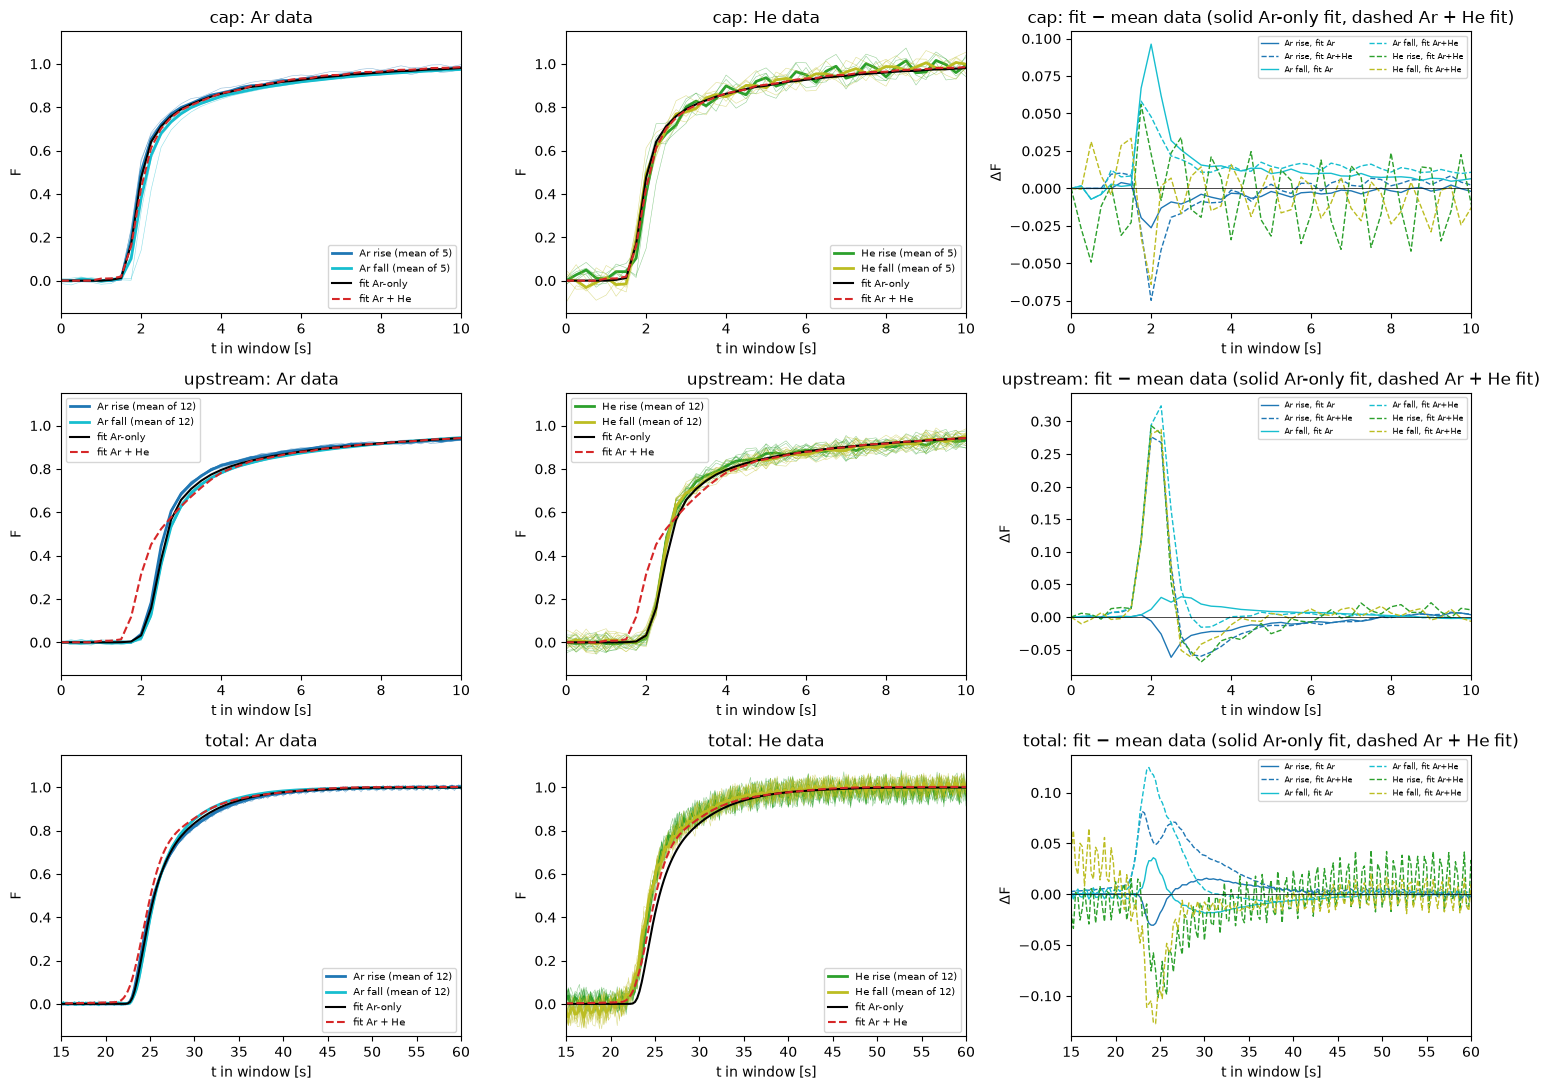

In [5]:
XLIM = {"cap": (0, 10), "upstream": (0, 10), "total": (15, 60)}
COLORS = {"Ar rise": "C0", "Ar fall": "C9", "He rise": "C2", "He fall": "C8"}
FIT_STYLE = {"Ar": dict(c="k", lw=1.5, label="fit Ar-only"), "Ar+He": dict(c="C3", lw=1.5, ls="--", label="fit Ar + He")}
b = run["Ar+He"]
fig, ax = plt.subplots(3, 3, figsize=(15, 11))
for i, s in enumerate(SECTIONS):
    t, F = b[f"t_out {s}"][0], F_of(b, s)
    for j, tracer in enumerate(("Ar", "He")):
        a = ax[i, j]
        for g, sl in GROUPS["Ar+He"].items():
            if g.startswith(tracer):
                a.plot(t, F[sl].T, c=COLORS[g], lw=0.4, alpha=0.5)
                a.plot(t, F[sl].mean(axis=0), c=COLORS[g], lw=2, label=f"{g} (mean of {F[sl].shape[0]})")
        for k in run:
            a.plot(t, fit[k][s], **FIT_STYLE[k])
        a.set(xlim=XLIM[s], ylim=(-0.15, 1.15), title=f"{s}: {tracer} data", xlabel="t in window [s]", ylabel="F")
        a.legend(fontsize=7)
    a = ax[i, 2]
    for g, sl in GROUPS["Ar+He"].items():
        for k in run:
            if k == "Ar" and g.startswith("He"):
                continue
            a.plot(t, fit[k][s] - F[sl].mean(axis=0), c=COLORS[g], ls="-" if k == "Ar" else "--", lw=1,
                   label=f"{g}, fit {k}")
    a.axhline(0, c="k", lw=0.5)
    a.set(xlim=XLIM[s], title=f"{s}: fit − mean data (solid Ar-only fit, dashed Ar + He fit)", xlabel="t in window [s]", ylabel="ΔF")
    a.legend(fontsize=6, ncol=2)
fig.tight_layout()

## 4. Kernels and bed inlet

E of the three sections for both runs and Alex's fit. The bed inlet is step ⊗ E_up (`F_bed_in` of the CCA runs; for Alex the same from his E_up). Alex's PTK model instead used the measured upstream signal, which has passed the capillary (PTK_model_reconciliation LOG F60); it is shown for comparison.

,kernel,fit,E(t=0) [1/s],Σ E dt,mean t [s],t of max [s]
0,E_up,Ar-only,0.000,0.996,0.959,0.500
1,E_down,Ar-only,0.000,0.997,23.114,21.250
2,E_cap,Ar-only,0.000,1.005,1.993,1.000
3,E_up,Ar + He,2.930,1.000,0.861,0.000
4,E_down,Ar + He,0.000,1.003,22.737,21.750
5,E_cap,Ar + He,0.038,0.999,1.884,1.000
6,E_up,Alex 2025-06-30,3.317,1.002,0.734,0.000
7,E_down,Alex 2025-06-30,0.000,1.005,22.911,22.000
8,E_cap,Alex 2025-06-30,0.093,0.996,1.930,1.000


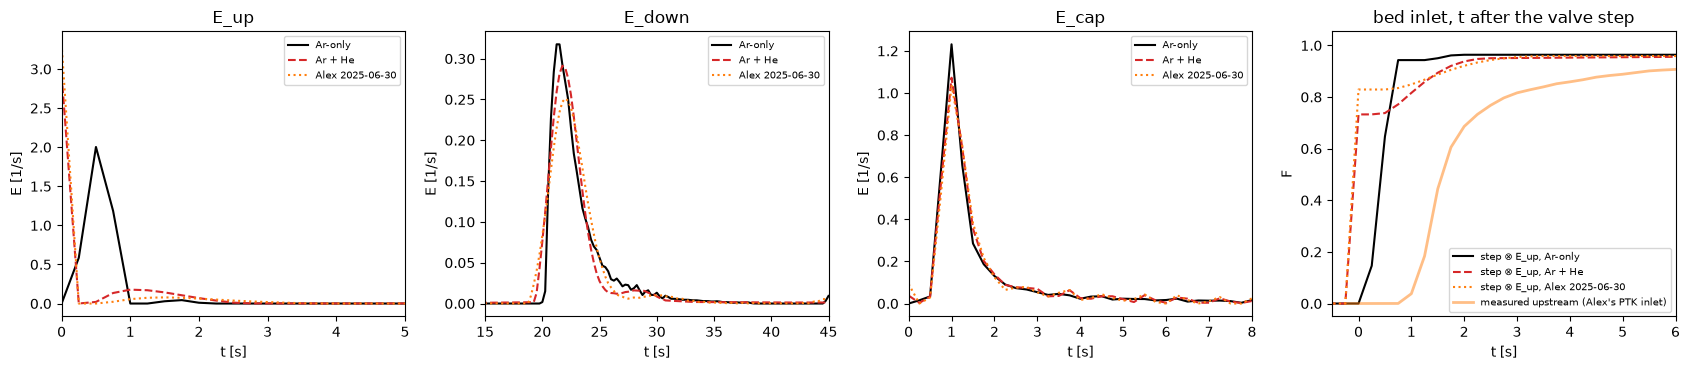

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
src = {"Ar-only": run["Ar"], "Ar + He": run["Ar+He"], "Alex 2025-06-30": alex}
style = {"Ar-only": dict(c="k"), "Ar + He": dict(c="C3", ls="--"), "Alex 2025-06-30": dict(c="C1", ls=":")}
rows = []
for k, r in src.items():
    for i, n in enumerate(("E_up", "E_down", "E_cap")):
        t, E = r["ts"][i], r["Es"][i]
        ax[i].plot(t, E, label=k, **style[k])
        rows.append({"kernel": n, "fit": k, "E(t=0) [1/s]": E[0], "Σ E dt": E.sum() * (t[1] - t[0]),
                     "mean t [s]": (t * E).sum() / E.sum(), "t of max [s]": t[np.argmax(E)]})
for i, (n, xl) in enumerate((("E_up", (0, 5)), ("E_down", (15, 45)), ("E_cap", (0, 8)))):
    ax[i].set(title=n, xlim=xl, xlabel="t [s]", ylabel="E [1/s]")
    ax[i].legend(fontsize=7)

# bed inlet: step at 1.0 s on the 0.25 s grid
dt = 0.25
t_step = np.arange(0, 35 + dt / 2, dt)
step = (t_step >= 1.0).astype(float)
def bed_inlet(E_up):
    xp = np.concatenate((np.zeros(E_up.size - 1), step))
    return np.convolve(xp, E_up)[E_up.size - 1 : E_up.size - 1 + step.size] * dt
for k, r in src.items():
    ax[3].plot(t_step - 1.0, bed_inlet(r["Es"][0]), label=f"step ⊗ E_up, {k}", **style[k])
U = alex["x_out upstream"][0::4, 0]
xin = alex["x_in upstream"][0::4, 0]
ax[3].plot(alex["t_out upstream"][0] - 0.25, ((U - xin[:, :1]) / (xin[:, -1:] - xin[:, :1])).mean(axis=0),
           c="C1", lw=2, alpha=0.5, label="measured upstream (Alex's PTK inlet)")
ax[3].set(title="bed inlet, t after the valve step", xlim=(-0.5, 6), xlabel="t [s]", ylabel="F")
ax[3].legend(fontsize=7)
fig.tight_layout()
pd.DataFrame(rows).style.format(precision=3)

## 5. Fit quality from the runs' metrics

max |ΔF| and RMS of the fitted chain against the mean data of each group (from `CCA_001.evaluate`, same numbers as section 3).

In [7]:
rows = []
for k in run:
    for s in SECTIONS:
        for g, m in metrics[k]["metrics"][s].items():
            rows.append({"fit": k, "section": s, "group": g, "max |ΔF|": m["max_abs_dF"], "RMS ΔF": m["rms_dF"],
                         "repeat std": m["repeat_std_max"], "rows": m["n_rows"]})
pd.DataFrame(rows).pivot_table(index=["section", "group"], columns="fit", values=["max |ΔF|", "RMS ΔF"]).style.format("{:.4f}")

## Findings (2026-10-30, from the outputs above)

**1. Same data.** The Ar rows of the Ar + He run are identical to the Ar-only run in all three sections (max |Δ| = 0 for
`x_out`, `x_in` and the time grids). The fit plot of the Ar + He run looks noisier only because it also shows the He rows.

**2. He is noisier in F because its step is small against its level, not because the MS is worse for He.** Plateau
noise in mole fraction: Ar ≈ 1.6–4.7·10⁻⁴ at its upper level (0.033–0.080), He ≈ 0.7–2.0·10⁻³ at 0.10–0.59; relative
to the level both are ≈ 0.35–0.8 %. But He switches only by Δ ≈ 0.03–0.07 on a base of 0.10–0.59, so its noise is
2.3–4.0 % of Δ, against 0.5–0.6 % for the upper Ar plateau and < 0.01 % for the Ar plateau at zero. The repeat
scatter in F follows: He 4–6 % (upstream, total), Ar ≈ 1 %.

**3. Ar + He fits Ar worse, and not only near the noise.**
- total system: He arrives earlier than Ar (section 3, bottom row). One kernel set compromises: on the Ar fall the
  Ar + He fit misses the mean data by up to 12 %, the Ar-only fit by 3.6 %.
- upstream: the Ar + He fit keeps a spike of E_up at t = 0 (2.93 1/s), the leftover of the direct-response start,
  as Alex's fit does (3.3 1/s, also Ar + He). Its response is ≈ 0.4 too high at t ≈ 2 s for all four groups (max
  |ΔF| 0.29 on the mean). The Ar-only fit removed the spike completely (E_up(0) = 0, peak at 0.5 s; max |ΔF| 1.9 %).
  **Cause (investigated 2026-10-30, refits of the upstream stage and one full refit, not part of this notebook):** an
  optimization artifact of fitting absolute mole fractions. He sits at x ≈ 0.26–0.59 and switches by only 0.03–0.07.
  With replicate padding, every He row (before and after the step) scales with ΣE·dt, so each Adam step moves He's
  whole signal by about its step size: at lr 4e-3 the fit oscillates, at 4e-4 (Alex) it is too slow to remove the
  direct-response start. The spike is not what the loss prefers: started from the Ar-only E_up at lr 4e-3 the loss
  even rose (6.7e-6 → 1.5e-5); at lr 4e-4 it settled lower without the spike (2.5e-6) than any fit that kept it.
  Fitting every row as deviation from its level before the step (same physics, ΣE free as before) removes it: full
  three-stage Ar + He refit, upstream max |ΔF| 0.29 → 0.045 (Ar rise 5.9 %, Ar-only fit 6.2 %), E_up(0) 2.93 → 0.37.
  Minibatching (32 + 6 rows) and the capillary kernel were ruled out.
- total system, physical: He arrives earlier than Ar only here (t50 of the data 24.5–24.75 s vs 25.5–25.75 s; in the
  capillary and upstream sections the t50 are equal). The Ar-only kernels miss He in the total system by 18–21 %
  (max), the shifted Ar + He refit still misses the Ar fall by 11 %. One E_down cannot serve both tracers.
- capillary: mixed. Ar rise 7.5 % (Ar + He) vs 2.6 % (Ar-only), Ar fall 5.8 % vs 9.6 %; the capillary repeats
  scatter by up to 14 %.

**4. Bed inlet.** Ar-only: step ⊗ E_up reaches 50 % ≈ 0.5 s after the step, with no instantaneous part. Ar + He
and Alex: ≈ 0.73–0.83 of the step passes instantly (the E_up spike). Alex's PTK model used neither: it used the
measured upstream signal, which has passed the capillary (50 % at ≈ 1.75 s after the step).

**For the PTK model (Ar response):** the Ar-only kernels are the consistent choice: same data, no start-up residue,
and the best Ar fit in every section except the capillary Ar fall.